In [ ]:
!pip install chromadb
!pip install langchain
#!pip install -U langchain-openai
#!pip install -U langchain-community pypdf
#!pip install openai
#!pip install faiss-cpu 
#!pip install tf-keras
#!pip install streamlit tensorflow openai pillow numpy
!pip install sentence-transformers
#!pip install python-docx
#!pip install PyPDF2
pip install pypdf2

SyntaxError: invalid syntax (1408018272.py, line 12)

In [ ]:
!pip install chromadb
!pip install sentence-transformers
!pip install langchain
!pip install langchain-community

In [ ]:
from PyPDF2 import PdfReader

reader = PdfReader("./test.pdf")
text = " ".join([page.extract_text() for page in reader.pages])

In [33]:
import pdfplumber

with pdfplumber.open("test.pdf") as pdf:
    text = " ".join([page.extract_text() for page in pdf.pages])

In [ ]:
import os
import pdfplumber
import docx
import pandas as pd
import openpyxl
import requests
from bs4 import BeautifulSoup
import urllib.parse
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm import tqdm

def extract_text_from_file(file_path):
    file_extension = os.path.splitext(file_path)[1].lower()

    try:
        if file_extension == '.pdf':
            with pdfplumber.open(file_path) as pdf:
                return " ".join([page.extract_text() or "" for page in pdf.pages])

        elif file_extension in ['.docx', '.doc']:
            doc = docx.Document(file_path)
            return "\n".join([paragraph.text for paragraph in doc.paragraphs])

        elif file_extension == '.txt':
            with open(file_path, 'r', encoding='utf-8') as txt_file:
                return txt_file.read()

        elif file_extension == '.html':
            with open(file_path, 'r', encoding='utf-8') as html_file:
                soup = BeautifulSoup(html_file, 'html.parser')
                return soup.get_text(separator=' ', strip=True)

        else:
            return ""

    except Exception as e:
        # print(f"Erreur lors du traitement de {file_path}: {e}")
        return ""

def download_linked_files(excel_path, download_dir):
    os.makedirs(download_dir, exist_ok=True)

    wb = openpyxl.load_workbook(excel_path, data_only=True)
    ws = wb.active  # Sélection de la première feuille

    downloaded_files = []

    for row in ws.iter_rows():
        for cell in row:
            if cell.hyperlink and cell.hyperlink.target:
                link = cell.hyperlink.target
                if not link.lower().endswith(('.pdf', '.docx', '.txt', '.html')):
                    continue
                try:
                    response = requests.get(link, timeout=10, verify=False)
                    if response.status_code == 200:
                        filename = os.path.basename(urllib.parse.urlparse(link).path)
                        if not filename:
                            filename = "file_" + str(len(downloaded_files) + 1) + ".pdf"

                        filepath = os.path.join(download_dir, filename)
                        with open(filepath, 'wb') as f:
                            f.write(response.content)

                        downloaded_files.append(filepath)
                except Exception as e:
                    print(f"Erreur de téléchargement pour {link}: {e}")

    return downloaded_files

def process_file(file_path):
    text = extract_text_from_file(file_path)
    return text if text else None

def process_directory(directory, output_file='corpus.txt', excel_download_dir='downloads', max_workers=4):
    all_texts = set()  # Utilisation d'un set pour éviter les doublons
    temp_output_file = output_file + '.tmp'

    # Traitement des fichiers Excel pour télécharger les fichiers liés
    # excel_files = [os.path.join(root, file) for root, _, files in os.walk(directory) for file in files if file.endswith('.xlsx')]

    # with ThreadPoolExecutor(max_workers=max_workers) as executor:
    #     future_to_excel = {executor.submit(download_linked_files, excel_path, excel_download_dir): excel_path for excel_path in excel_files}

    #     for future in tqdm(as_completed(future_to_excel), total=len(future_to_excel), desc="Téléchargement des fichiers Excel"):
    #         linked_files = future.result()
    #         for linked_file in linked_files:
    #             text = process_file(linked_file)
    #             if text:
    #                 all_texts.add(text)
    #                 with open(temp_output_file, 'a', encoding='utf-8') as f:
    #                     f.write(text + "\n\n")

    # Traitement des fichiers non Excel
    non_excel_files = [os.path.join(root, file) for root, _, files in os.walk(directory) for file in files if not file.endswith('.xlsx')]

    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        future_to_file = {executor.submit(process_file, file_path): file_path for file_path in non_excel_files}

        for future in tqdm(as_completed(future_to_file), total=len(future_to_file), desc="Extraction de texte"):
            text = future.result()
            if text:
                all_texts.add(text)
                with open(temp_output_file, 'a', encoding='utf-8') as f:
                    f.write(text + "\n\n")

    # Renommer le fichier temporaire en fichier final
    os.rename(temp_output_file, output_file)

    print(f"Corpus créé avec {len(all_texts)} documents")
    return list(all_texts)

# Utilisation
directory_path = '../data/'
text = process_directory(directory_path, max_workers=8, excel_download_dir='../data/downloads', output_file='../data/corpus.txt')


Extraction de texte:  88%|████████▊ | 987/1123 [1:53:54<21:09:35, 560.11s/it]

## Preprocess text

In [ ]:
from nltk.corpus import stopwords
import nltk
import re

# Ensure stopwords are downloaded
nltk.download('stopwords')

In [1]:
from bs4 import BeautifulSoup
from tqdm.notebook import tqdm
import re

def review_to_words(review, remove_stopwords=False):
    # supprimer des liens hypertextes
    review = re.sub(r"http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\(\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+", " ", review)
    # supprimer des balises html
    review_text = BeautifulSoup(review, "lxml").get_text()
    # remplacer les caractères autres que des lettres par des expaces
    review_text = re.sub("[^a-zA-Z]", " ", review_text)
    # mettre en minuscules et convertir en liste de mots
    words = review_text.lower().split()
    if remove_stopwords:
        # supprimer les mots vides de la langue anglaise
        words = [w for w in words if not w in stopwords.words("english")]
    return(words)

In [2]:
text = open('../data/corpus.txt.tmp', 'r', encoding='utf-8').read()

text = review_to_words(text)

In [4]:
from langchain.text_splitter import RecursiveCharacterTextSplitter

text_str = " ".join(text)

splitter = RecursiveCharacterTextSplitter(chunk_size=512, chunk_overlap=50)
docs = splitter.split_text(text_str)

In [5]:
from langchain.vectorstores import Chroma
from langchain.embeddings import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

vector_db = Chroma.from_texts(docs, embeddings, persist_directory="base_donnee")

C:\Users\jforc\AppData\Local\Temp\ipykernel_26828\1933219471.py:4: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-huggingface package and should be used instead. To use it run `pip install -U :class:`~langchain-huggingface` and import as `from :class:`~langchain_huggingface import HuggingFaceEmbeddings``.
  embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
c:\Users\jforc\Desktop\data battle\rag\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\jforc\AppData\Local\Temp\ipykernel_26828\181956510.py:8: LangChainDeprecationWarning: The class `Chroma` was deprecated in LangChain 0.2.9 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-chroma package and should be used instead. To use it run `pip install -U :class:`~langchain-chroma` and import as `from :class:`~langchain_chroma import Chroma``.
  vector_db = Chroma(persist_directory="base_donnee", embedding_function=embeddings)


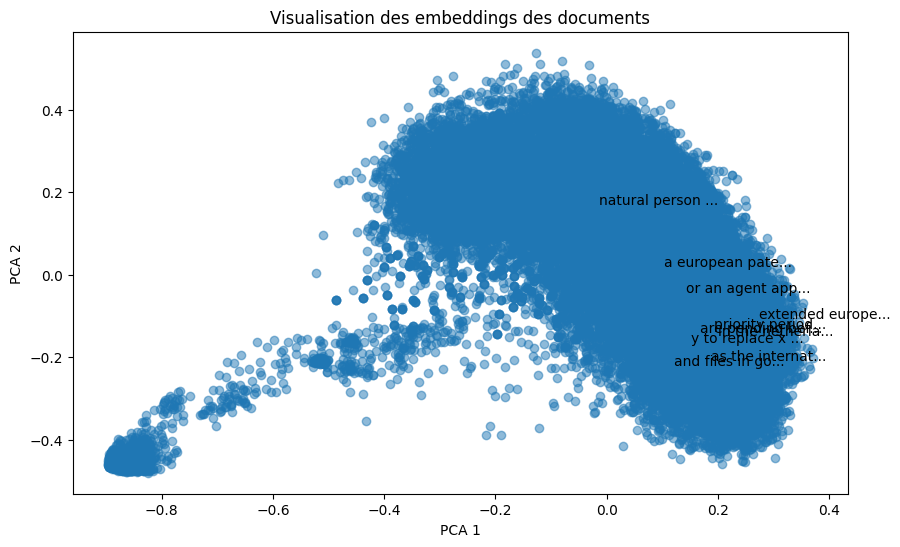

In [6]:
from langchain.vectorstores import Chroma
from langchain.embeddings import HuggingFaceEmbeddings
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Charger la base existante
embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
vector_db = Chroma(persist_directory="base_donnee", embedding_function=embeddings)

# Récupérer les données stockées
collection = vector_db._client.get_collection("langchain")
data = collection.get(include=["embeddings", "documents", "metadatas"])

# Visualisation des embeddings avec PCA
pca = PCA(n_components=2)
embeddings_2d = pca.fit_transform(data["embeddings"])

plt.figure(figsize=(10, 6))
plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], alpha=0.5)
for i, txt in enumerate(data["documents"][:10]):  # Afficher les 10 premiers textes
    plt.annotate(txt[:15] + "...", (embeddings_2d[i, 0], embeddings_2d[i, 1]))
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Visualisation des embeddings des documents")
plt.show()

In [ ]:
from rag_model import parse_qcm_response, build_prompt
from langchain.chat_models import ChatOpenAI
from langchain.chains import RetrievalQA
from langchain.vectorstores import Chroma

# cle_api_openai = ""

def generate_and_store_questions(question_type="QCM", theme_name="Général", level="débutant", nbre=5):
    prompt = build_prompt(question_type, theme_name, level, nbre)
    
    vector_db = Chroma(persist_directory="base_donnee", embedding_function=embeddings)

    llm = ChatOpenAI(
        model_name="gpt-3.5-turbo",  # ou "gpt-3.5-turbo" selon le modèle souhaité
        # openai_api_key=""
    )

    # Le reste reste identique
    qa = RetrievalQA.from_chain_type(
        llm=llm,
        chain_type="stuff",
        retriever=vector_db.as_retriever(search_kwargs={"k": 3}),
    )

    response = qa.run(prompt)
    
    if question_type == "QCM":
        question, choices, correct = parse_qcm_response(response)
        thematique, _ = Thematique.objects.get_or_create(nom=theme_name)
        exercice = Exercice.objects.create(titre=question, description="", difficulte=level, dureeEstimee=10, thematique=thematique)
        Question.objects.create(enonce=question, pointMax=1, exercice=exercice)
        return "QCM enregistré avec succès."
    else:
        return "Format non pris en charge pour l'instant."

In [ ]:
from langchain.chat_models import ChatOpenAI
from langchain.chains import RetrievalQA
from langchain.vectorstores import Chroma
from langchain.embeddings import HuggingFaceEmbeddings
# Configuration pour OpenAI direct
vector_db = Chroma(persist_directory="base_donnee", embedding_function=embeddings)

llm = ChatOpenAI(
    model_name="gpt-3.5-turbo",  # ou "gpt-3.5-turbo" selon le modèle souhaité
    # openai_api_key=""
)

# Le reste reste identique
qa = RetrievalQA.from_chain_type(
    llm=llm,
    chain_type="stuff",
    retriever=vector_db.as_retriever(search_kwargs={"k": 3}),
)

prompt = """
Generate a 2-question multiple-choice quiz on the topic of "contract law," beginner level.

Your answer MUST strictly follow this format:

Question: What is the keyword used to define a function in Python?
A. define
B. function
C. def
D. fun
Correct answer: C
"""

response = qa.run(prompt)

In [16]:
print(response)

Question: What is a contract?
A. A written document
B. A verbal agreement
C. A legally binding agreement between two or more parties
D. A casual promise
Correct answer: C

Question: What is an offer in contract law?
A. A request for payment
B. A proposal to enter into a contract
C. A demand for performance
D. An agreement to terminate a contract
Correct answer: B


In [2]:
result = """
Question: What is a contract?
A. A written document
B. A verbal agreement
C. A legally binding agreement between two or more parties
D. A casual promise
Correct answer: C

Question: What is an offer in contract law?
A. A request for payment
B. A proposal to enter into a contract
C. A demand for performance
D. An agreement to terminate a contract
Correct answer: B
"""

def parse_qcm_response(response_text):
    questions = []
    lines = response_text.strip().splitlines()
    question, choices, correct = "", {}, ""
    for line in lines:
        line = line.strip()
        if line.lower().startswith("question"):
            # Si une nouvelle question commence, sauvegardez la précédente
            if question:
                questions.append({"question": question, "choices": choices, "correct": correct})
                question, choices, correct = "", {}, ""  # Réinitialiser pour la prochaine question
            question = line.split(":", 1)[-1].strip()
        elif line.startswith(("A.", "B.", "C.", "D.")):
            key, val = line.split(".", 1)
            choices[key.strip()] = val.strip()
        elif "correct answer" in line.lower():
            correct = line.split(":")[-1].strip()
    # Ajouter la dernière question si elle existe
    if question:
        questions.append({"question": question, "choices": choices, "correct": correct})
    return questions

def parse_analyse_response(response_text):
    questions = []
    lines = response_text.strip().split("\n")
    question, instructions = "", ""
    for line in lines:
        line = line.strip()
        if line.lower().startswith("question"):
            # Si une nouvelle question commence, sauvegardez la précédente
            if question:
                questions.append({"question": question, "instructions": instructions})
                question, instructions = "", ""  # Réinitialiser pour la prochaine question
            question = line.split(":", 1)[-1].strip()
        elif line.lower().startswith("consignes"):
            instructions = line.split(":", 1)[-1].strip()
    # Ajouter la dernière question si elle existe
    if question:
        questions.append({"question": question, "instructions": instructions})
    return questions

questions = parse_qcm_response(result)
questions

[{'question': 'What is a contract?',
  'choices': {'A': 'A written document',
   'B': 'A verbal agreement',
   'C': 'A legally binding agreement between two or more parties',
   'D': 'A casual promise'},
  'correct': 'C'},
 {'question': 'What is an offer in contract law?',
  'choices': {'A': 'A request for payment',
   'B': 'A proposal to enter into a contract',
   'C': 'A demand for performance',
   'D': 'An agreement to terminate a contract'},
  'correct': 'B'}]